In [1]:
!pip install pandas numpy matplotlib seaborn


Dataset created successfully!
Rows: 2000
Columns: 12
Saved to: ..\data\customer_churn.csv

========== FIRST 5 ROWS ==========
  Customer_ID  Age  Gender  Tenure_Months        Contract    Payment_Method  \
0   CUST10000   56    Male             38        One Year  Electronic Check   
1   CUST10001   69  Female             53  Month-to-Month     Bank Transfer   
2   CUST10002   46  Female             61        One Year  Electronic Check   
3   CUST10003   32  Female             36        One Year  Electronic Check   
4   CUST10004   60  Female             40  Month-to-Month     Bank Transfer   

  Internet_Service Subscription  Monthly_Charges  Total_Charges  \
0      Fiber Optic        Basic           145.76        5541.60   
1              DSL     Standard           148.22        7910.98   
2              DSL     Standard            91.42        5597.77   
3      Fiber Optic        Basic            29.19        1079.54   
4      Fiber Optic     Standard            90.33        3704.25 

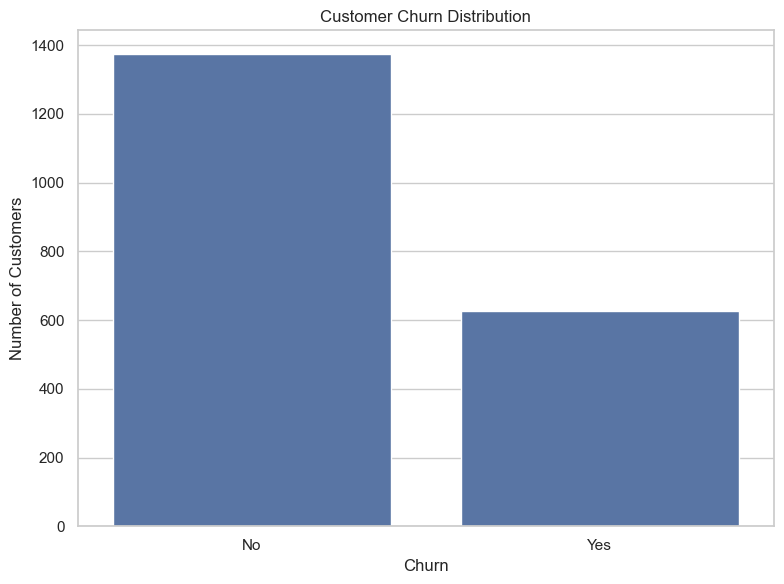

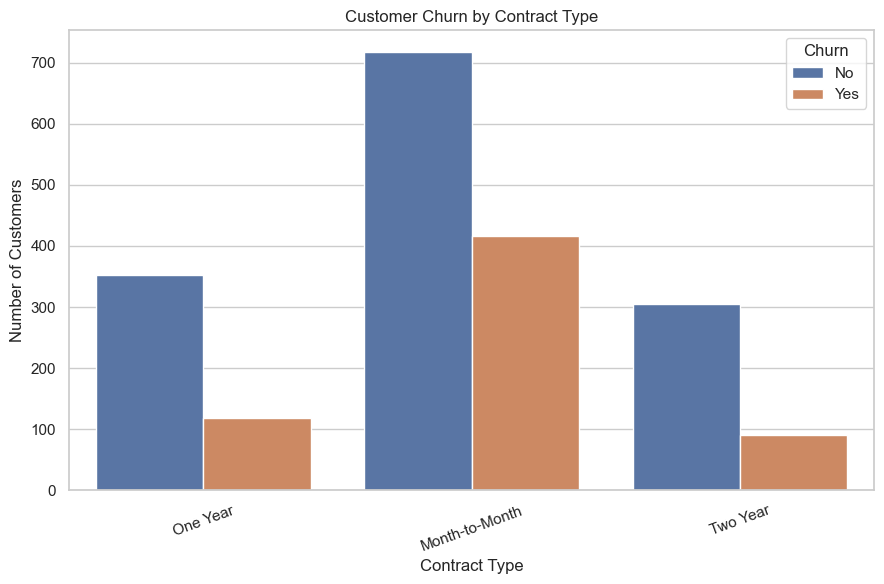

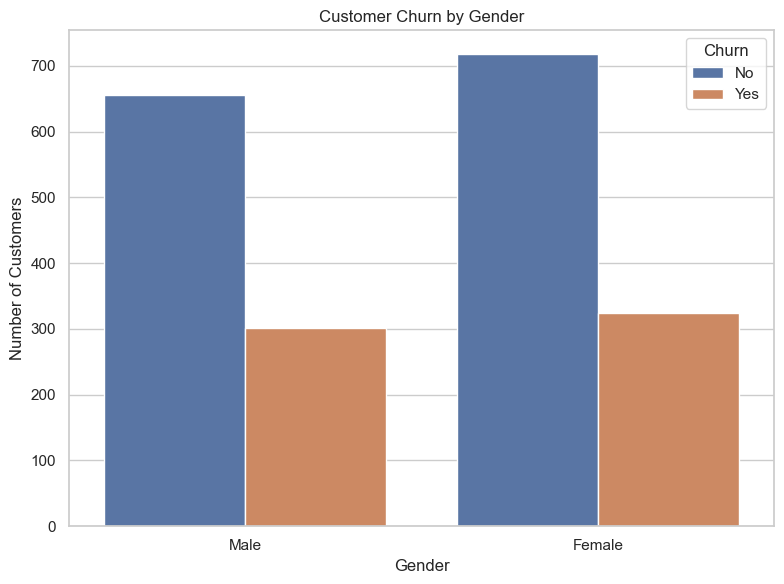

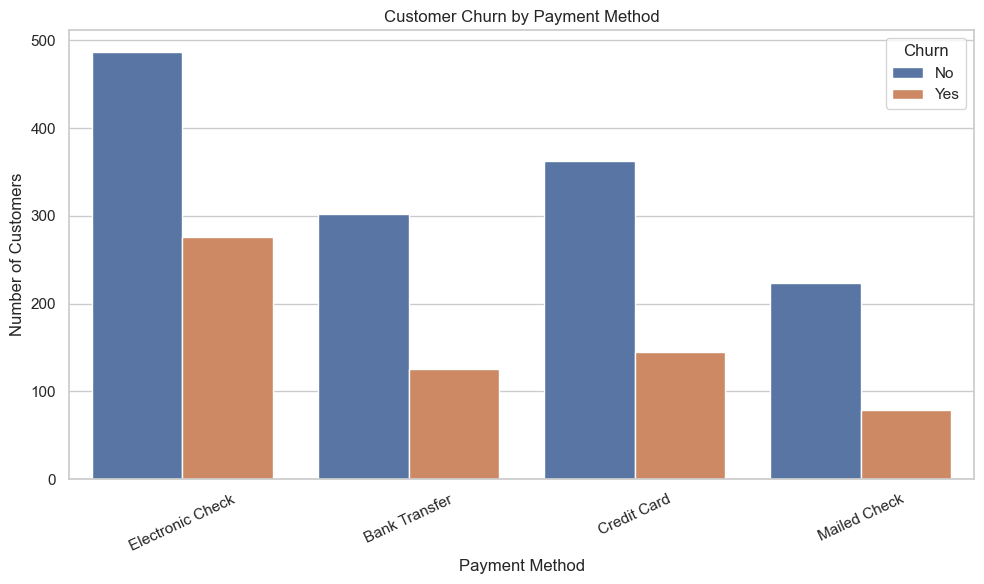

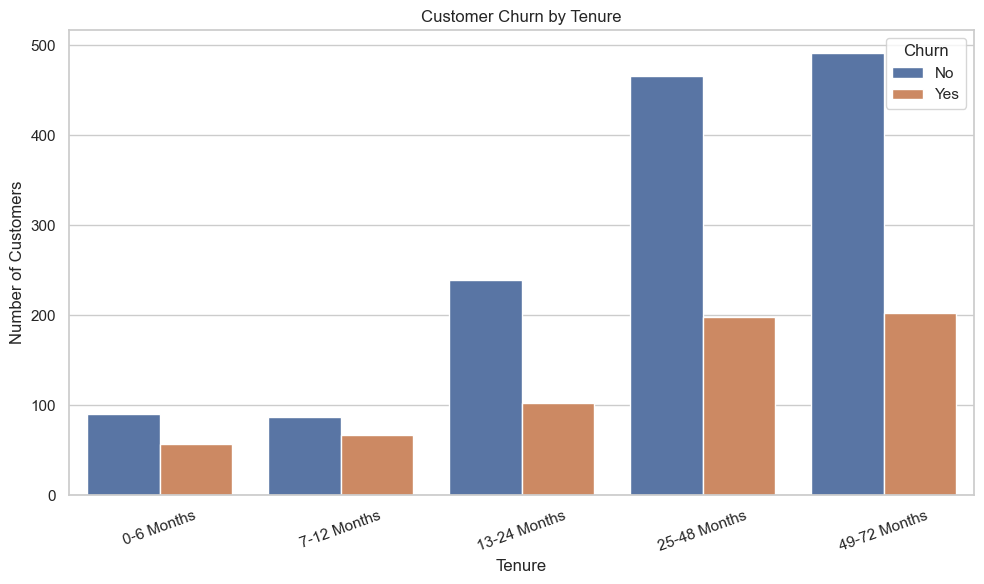

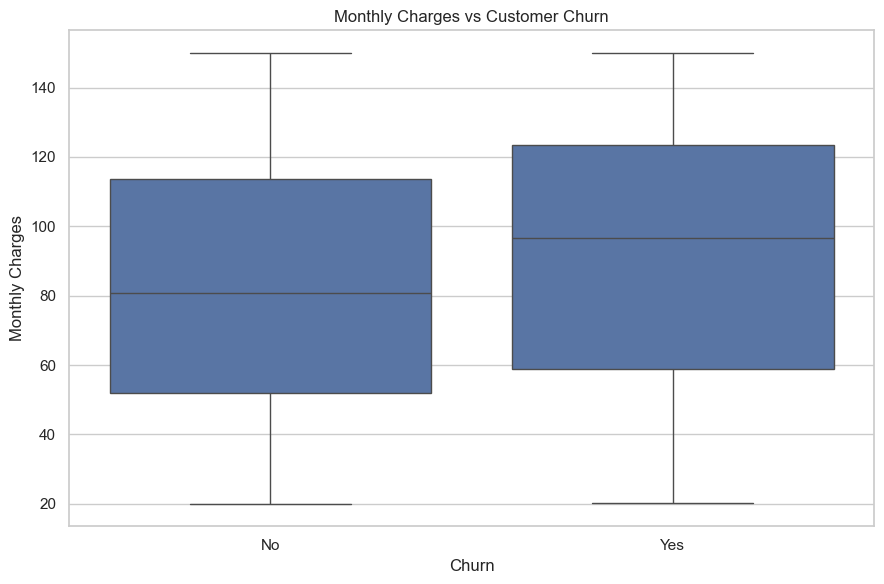

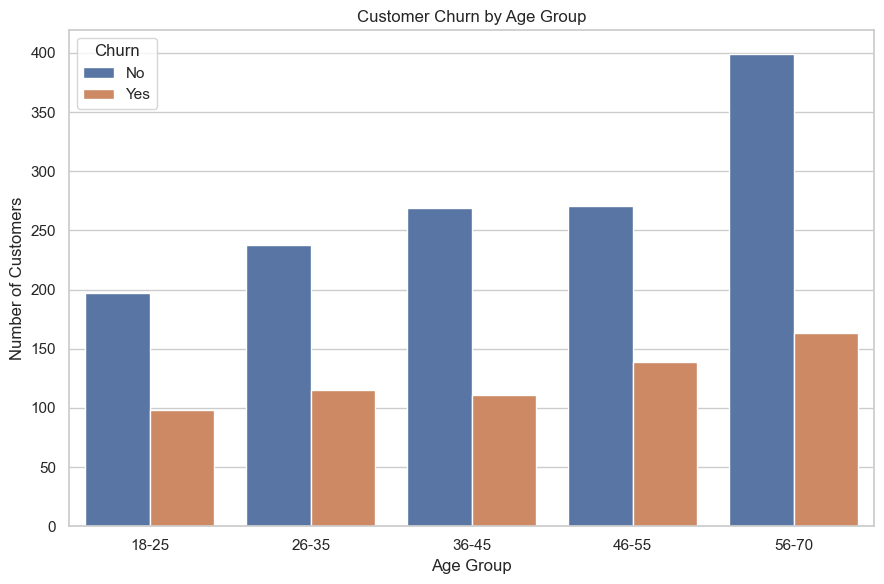

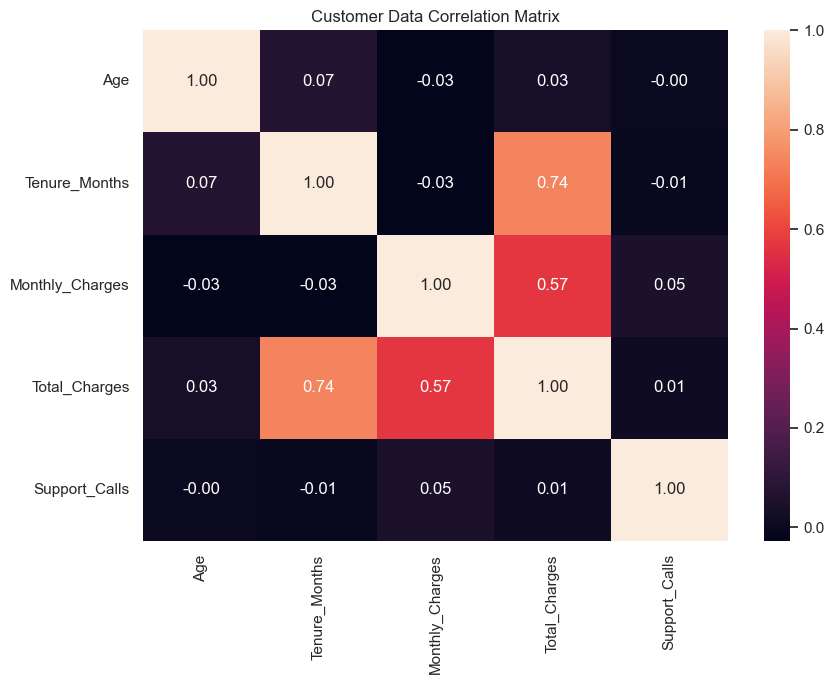



                 BUSINESS INSIGHTS
1. Overall churn rate: 31.30%
2. Highest churn contract: Month-to-Month
3. Highest churn payment method: Electronic Check
4. Highest churn age group: 46-55
5. Highest churn tenure group: 7-12 Months
6. Highest churn subscription: Premium
7. Average monthly charge: ₹85.35
8. Average customer tenure: 37.20 months
9. High-risk customers identified: 437

Customer Churn Analysis completed successfully! ✅


In [2]:
# ============================================================
# CUSTOMER CHURN DATA ANALYSIS
# Project 2 - Data Analytics Portfolio
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

BASE_DIR = Path("..")

DATA_DIR = BASE_DIR / "data"
VISUALS_DIR = BASE_DIR / "visuals"

DATA_DIR.mkdir(parents=True, exist_ok=True)
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. CREATE SYNTHETIC CUSTOMER DATASET
# ------------------------------------------------------------

np.random.seed(42)

n = 2000

customer_ids = [
    f"CUST{10000+i}"
    for i in range(n)
]

age = np.random.randint(18, 71, n)

gender = np.random.choice(
    ["Male", "Female"],
    n
)

tenure = np.random.randint(
    1,
    73,
    n
)

contract = np.random.choice(
    ["Month-to-Month", "One Year", "Two Year"],
    n,
    p=[0.55, 0.25, 0.20]
)

payment_method = np.random.choice(
    [
        "Electronic Check",
        "Credit Card",
        "Bank Transfer",
        "Mailed Check"
    ],
    n,
    p=[0.40, 0.25, 0.20, 0.15]
)

internet_service = np.random.choice(
    [
        "DSL",
        "Fiber Optic",
        "No Internet"
    ],
    n,
    p=[0.35, 0.50, 0.15]
)

subscription = np.random.choice(
    [
        "Basic",
        "Standard",
        "Premium"
    ],
    n,
    p=[0.40, 0.40, 0.20]
)

monthly_charges = np.round(
    np.random.uniform(20, 150, n),
    2
)

total_charges = np.round(
    monthly_charges * tenure +
    np.random.uniform(0, 100, n),
    2
)

support_calls = np.random.randint(
    0,
    11,
    n
)

# ------------------------------------------------------------
# 3. CREATE CHURN PROBABILITY
# ------------------------------------------------------------

churn_probability = (
    0.10
    + (monthly_charges > 100) * 0.12
    + (contract == "Month-to-Month") * 0.15
    + (payment_method == "Electronic Check") * 0.08
    + (tenure < 12) * 0.12
    + (support_calls >= 7) * 0.08
)

churn_probability = np.clip(
    churn_probability,
    0.05,
    0.75
)

churn = np.random.random(n) < churn_probability

churn = np.where(
    churn,
    "Yes",
    "No"
)

# ------------------------------------------------------------
# 4. CREATE DATAFRAME
# ------------------------------------------------------------

df = pd.DataFrame({

    "Customer_ID": customer_ids,

    "Age": age,

    "Gender": gender,

    "Tenure_Months": tenure,

    "Contract": contract,

    "Payment_Method": payment_method,

    "Internet_Service": internet_service,

    "Subscription": subscription,

    "Monthly_Charges": monthly_charges,

    "Total_Charges": total_charges,

    "Support_Calls": support_calls,

    "Churn": churn
})

# ------------------------------------------------------------
# 5. SAVE DATASET
# ------------------------------------------------------------

csv_path = DATA_DIR / "customer_churn.csv"

df.to_csv(
    csv_path,
    index=False
)

print("Dataset created successfully!")
print(f"Rows: {len(df)}")
print(f"Columns: {len(df.columns)}")
print(f"Saved to: {csv_path}")

# ------------------------------------------------------------
# 6. LOAD DATA
# ------------------------------------------------------------

df = pd.read_csv(csv_path)

print("\n========== FIRST 5 ROWS ==========")

print(df.head())

# ------------------------------------------------------------
# 7. DATASET INFORMATION
# ------------------------------------------------------------

print("\n========== DATASET INFO ==========")

df.info()

# ------------------------------------------------------------
# 8. MISSING VALUES
# ------------------------------------------------------------

print("\n========== MISSING VALUES ==========")

print(df.isnull().sum())

# ------------------------------------------------------------
# 9. DUPLICATES
# ------------------------------------------------------------

print("\n========== DUPLICATES ==========")

print(
    "Duplicate rows:",
    df.duplicated().sum()
)

# ------------------------------------------------------------
# 10. STATISTICS
# ------------------------------------------------------------

print("\n========== STATISTICS ==========")

print(
    df.describe()
)

# ------------------------------------------------------------
# 11. BASIC KPIs
# ------------------------------------------------------------

total_customers = len(df)

churned_customers = (
    df["Churn"] == "Yes"
).sum()

active_customers = (
    df["Churn"] == "No"
).sum()

churn_rate = (
    churned_customers /
    total_customers
) * 100

average_monthly_charge = (
    df["Monthly_Charges"].mean()
)

average_tenure = (
    df["Tenure_Months"].mean()
)

print("\n========== CUSTOMER KPIs ==========")

print(
    f"Total Customers       : {total_customers:,}"
)

print(
    f"Churned Customers     : {churned_customers:,}"
)

print(
    f"Active Customers      : {active_customers:,}"
)

print(
    f"Churn Rate            : {churn_rate:.2f}%"
)

print(
    f"Average Monthly Charge: ₹{average_monthly_charge:,.2f}"
)

print(
    f"Average Tenure        : {average_tenure:.2f} months"
)

# ------------------------------------------------------------
# 12. CHURN DISTRIBUTION
# ------------------------------------------------------------

churn_distribution = (
    df["Churn"]
    .value_counts()
)

print("\n========== CHURN DISTRIBUTION ==========")

print(
    churn_distribution
)

# ------------------------------------------------------------
# 13. CHURN BY GENDER
# ------------------------------------------------------------

gender_churn = pd.crosstab(
    df["Gender"],
    df["Churn"],
    normalize="index"
) * 100

print("\n========== CHURN BY GENDER ==========")

print(
    gender_churn.round(2)
)

# ------------------------------------------------------------
# 14. CHURN BY CONTRACT
# ------------------------------------------------------------

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("\n========== CHURN BY CONTRACT ==========")

print(
    contract_churn.round(2)
)

# ------------------------------------------------------------
# 15. CHURN BY PAYMENT METHOD
# ------------------------------------------------------------

payment_churn = pd.crosstab(
    df["Payment_Method"],
    df["Churn"],
    normalize="index"
) * 100

print("\n========== CHURN BY PAYMENT METHOD ==========")

print(
    payment_churn.round(2)
)

# ------------------------------------------------------------
# 16. CHURN BY SUBSCRIPTION
# ------------------------------------------------------------

subscription_churn = pd.crosstab(
    df["Subscription"],
    df["Churn"],
    normalize="index"
) * 100

print("\n========== CHURN BY SUBSCRIPTION ==========")

print(
    subscription_churn.round(2)
)

# ------------------------------------------------------------
# 17. CHURN BY INTERNET SERVICE
# ------------------------------------------------------------

internet_churn = pd.crosstab(
    df["Internet_Service"],
    df["Churn"],
    normalize="index"
) * 100

print("\n========== CHURN BY INTERNET SERVICE ==========")

print(
    internet_churn.round(2)
)

# ------------------------------------------------------------
# 18. AGE GROUP ANALYSIS
# ------------------------------------------------------------

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 70],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-70"
    ]
)

age_churn = pd.crosstab(
    df["Age_Group"],
    df["Churn"],
    normalize="index"
) * 100

print("\n========== CHURN BY AGE GROUP ==========")

print(
    age_churn.round(2)
)

# ------------------------------------------------------------
# 19. TENURE GROUP ANALYSIS
# ------------------------------------------------------------

df["Tenure_Group"] = pd.cut(
    df["Tenure_Months"],
    bins=[0, 6, 12, 24, 48, 72],
    labels=[
        "0-6 Months",
        "7-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-72 Months"
    ]
)

tenure_churn = pd.crosstab(
    df["Tenure_Group"],
    df["Churn"],
    normalize="index"
) * 100

print("\n========== CHURN BY TENURE ==========")

print(
    tenure_churn.round(2)
)

# ------------------------------------------------------------
# 20. MONTHLY CHARGES ANALYSIS
# ------------------------------------------------------------

churn_charges = (
    df.groupby("Churn")["Monthly_Charges"]
    .mean()
)

print("\n========== AVERAGE MONTHLY CHARGES ==========")

print(
    churn_charges.round(2)
)

# ------------------------------------------------------------
# 21. SUPPORT CALL ANALYSIS
# ------------------------------------------------------------

support_churn = (
    df.groupby("Churn")["Support_Calls"]
    .mean()
)

print("\n========== AVERAGE SUPPORT CALLS ==========")

print(
    support_churn.round(2)
)

# ------------------------------------------------------------
# 22. HIGH-RISK CUSTOMER SEGMENT
# ------------------------------------------------------------

high_risk = df[
    (
        (df["Contract"] == "Month-to-Month") &
        (df["Monthly_Charges"] > 100)
    )
]

print("\n========== HIGH-RISK CUSTOMERS ==========")

print(
    f"High-risk customers: {len(high_risk)}"
)

# ------------------------------------------------------------
# 23. TOP HIGH-RISK CUSTOMERS
# ------------------------------------------------------------

top_risk_customers = (
    df[
        (df["Churn"] == "Yes")
    ]
    .sort_values(
        by="Monthly_Charges",
        ascending=False
    )
    .head(10)
)

print("\n========== TOP 10 CHURNED CUSTOMERS ==========")

print(
    top_risk_customers[
        [
            "Customer_ID",
            "Age",
            "Contract",
            "Monthly_Charges",
            "Tenure_Months",
            "Support_Calls",
            "Churn"
        ]
    ]
)

# ============================================================
# VISUALIZATIONS
# ============================================================

sns.set_theme(
    style="whitegrid"
)

# ------------------------------------------------------------
# 24. CHURN DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title(
    "Customer Churn Distribution"
)

plt.xlabel(
    "Churn"
)

plt.ylabel(
    "Number of Customers"
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "churn_distribution.png",
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 25. CHURN BY CONTRACT
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title(
    "Customer Churn by Contract Type"
)

plt.xlabel(
    "Contract Type"
)

plt.ylabel(
    "Number of Customers"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "churn_by_contract.png",
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 26. CHURN BY GENDER
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.countplot(
    data=df,
    x="Gender",
    hue="Churn"
)

plt.title(
    "Customer Churn by Gender"
)

plt.xlabel(
    "Gender"
)

plt.ylabel(
    "Number of Customers"
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "churn_by_gender.png",
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 27. CHURN BY PAYMENT METHOD
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Payment_Method",
    hue="Churn"
)

plt.title(
    "Customer Churn by Payment Method"
)

plt.xlabel(
    "Payment Method"
)

plt.ylabel(
    "Number of Customers"
)

plt.xticks(
    rotation=25
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "churn_by_payment.png",
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 28. CHURN BY TENURE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Tenure_Group",
    hue="Churn"
)

plt.title(
    "Customer Churn by Tenure"
)

plt.xlabel(
    "Tenure"
)

plt.ylabel(
    "Number of Customers"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "churn_by_tenure.png",
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 29. MONTHLY CHARGES VS CHURN
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Churn",
    y="Monthly_Charges"
)

plt.title(
    "Monthly Charges vs Customer Churn"
)

plt.xlabel(
    "Churn"
)

plt.ylabel(
    "Monthly Charges"
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "monthly_charges_churn.png",
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 30. AGE GROUP CHURN
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x="Age_Group",
    hue="Churn"
)

plt.title(
    "Customer Churn by Age Group"
)

plt.xlabel(
    "Age Group"
)

plt.ylabel(
    "Number of Customers"
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "churn_by_age_group.png",
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 31. CORRELATION HEATMAP
# ------------------------------------------------------------

numeric_columns = [
    "Age",
    "Tenure_Months",
    "Monthly_Charges",
    "Total_Charges",
    "Support_Calls"
]

correlation = (
    df[numeric_columns]
    .corr()
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title(
    "Customer Data Correlation Matrix"
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "correlation_matrix.png",
    dpi=300
)

plt.show()

# ============================================================
# BUSINESS INSIGHTS
# ============================================================

highest_contract_churn = (
    contract_churn["Yes"]
    .idxmax()
)

highest_payment_churn = (
    payment_churn["Yes"]
    .idxmax()
)

highest_age_churn = (
    age_churn["Yes"]
    .idxmax()
)

highest_tenure_churn = (
    tenure_churn["Yes"]
    .idxmax()
)

highest_subscription_churn = (
    subscription_churn["Yes"]
    .idxmax()
)

print("\n")
print("=" * 65)
print("                 BUSINESS INSIGHTS")
print("=" * 65)

print(
    f"1. Overall churn rate: {churn_rate:.2f}%"
)

print(
    f"2. Highest churn contract: "
    f"{highest_contract_churn}"
)

print(
    f"3. Highest churn payment method: "
    f"{highest_payment_churn}"
)

print(
    f"4. Highest churn age group: "
    f"{highest_age_churn}"
)

print(
    f"5. Highest churn tenure group: "
    f"{highest_tenure_churn}"
)

print(
    f"6. Highest churn subscription: "
    f"{highest_subscription_churn}"
)

print(
    f"7. Average monthly charge: "
    f"₹{average_monthly_charge:,.2f}"
)

print(
    f"8. Average customer tenure: "
    f"{average_tenure:.2f} months"
)

print(
    f"9. High-risk customers identified: "
    f"{len(high_risk)}"
)

print("=" * 65)

print(
    "\nCustomer Churn Analysis completed successfully! ✅"
)